# Deep Learning Baseline: Long Short-Term Memory (LSTM) Model for Brent Crude Oil Price Forecasting

This notebook implements a **Deep Learning (LSTM)** model for predicting weekly Brent Crude Oil prices.

### Workflow:
1. Data loading and alignment with EDA pipeline (`data_collection_cleaning_EDA.ipynb`).
2. Feature scaling with `MinMaxScaler` fitted **strictly on training set** to prevent data leakage.
3. Sliding window sequence construction (Lookback = 4 weeks).
4. TensorFlow/Keras 2-layer LSTM architecture build and training with early stopping.
5. Evaluation on 20% chronological test set (RMSE, MAE, MAPE, $R^2$, Directional Accuracy).
6. Visualizing actual vs predicted prices and exporting predictions for Master Comparison.

Pulling Financial Market Data...
Fetching market data from 2016-01-01 to 2026-07-29


/var/folders/2c/yb6xjdp11v57x1r5bk7tndtm0000gn/T/ipykernel_70299/359705254.py:13: FutureWarning: YF.download() has changed argument auto_adjust default to True
  raw_data = yf.download(tickers, start=start_date, end=end_date)['Close']



[                       0%                       ]


[**********************50%                       ]  2 of 4 completed


[**********************75%***********            ]  3 of 4 completed


[*********************100%***********************]  4 of 4 completed

Downsampling to uniform weekly frequency (Friday close)
Pulling OPEC+ Supply Data...


Merging into Master Matrix...

--- Dynamically Pulled Cleaned Weekly Dataset ---
            Brent_Crude  WTI_Crude  US_Dollar_Index  VIX_Index  \
2026-07-03    71.800003  68.690002       100.860001  16.150000   
2026-07-10    76.010002  71.410004       100.970001  15.030000   
2026-07-17    88.099998  82.489998       100.750000  18.770000   
2026-07-24    96.779999  89.309998       101.430000  18.700001   
2026-07-31    84.089996  79.260002       101.510002  18.670000   

            OPEC_Plus_Production  
2026-07-03             27.516865  
2026-07-10             27.516865  
2026-07-17             27.516865  
2026-07-24             27.516865  
2026-07-31             27.516865  
--- Summary Statistics ---
       Brent_Crude   WTI_Crude  US_Dollar_Index   VIX_Index  \
count   552.000000  552.000000       552.000000  552.000000   
mean     69.077319   64.734221        98.563678   18.318424   
std      18.298541   17.865778         4.895742    7.020733   
min      21.440001   16.940001   

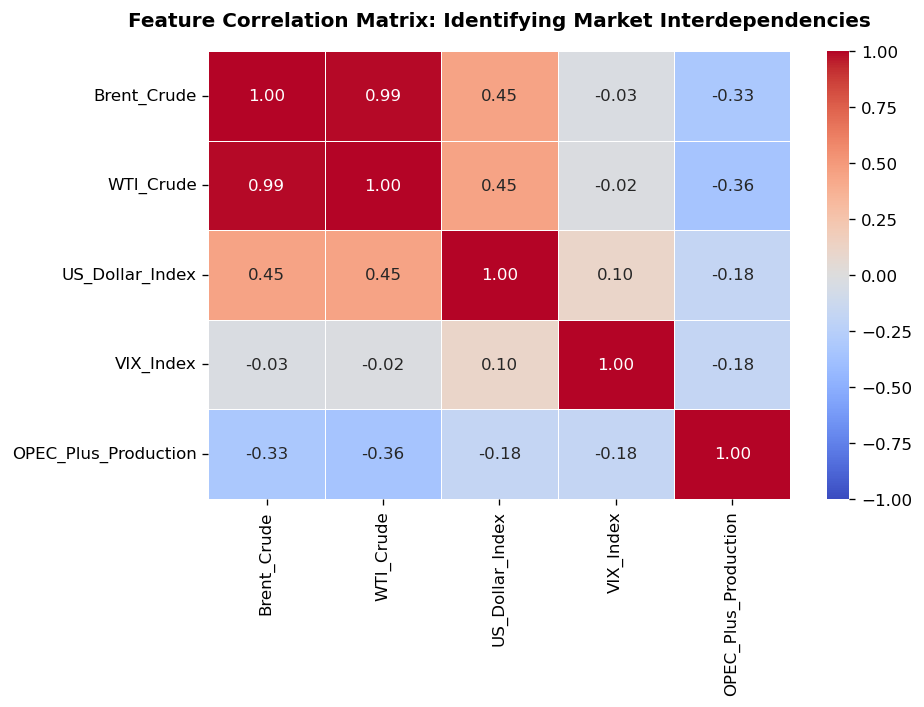

Normalization complete! New columns added to master_dataset.

--- Raw vs Normalized Dataset ---
            Brent_Crude  WTI_Crude  US_Dollar_Index  VIX_Index  \
2026-07-03    71.800003  68.690002       100.860001  16.150000   
2026-07-10    76.010002  71.410004       100.970001  15.030000   
2026-07-17    88.099998  82.489998       100.750000  18.770000   
2026-07-24    96.779999  89.309998       101.430000  18.700001   
2026-07-31    84.089996  79.260002       101.510002  18.670000   

            OPEC_Plus_Production  
2026-07-03             27.516865  
2026-07-10             27.516865  
2026-07-17             27.516865  
2026-07-24             27.516865  
2026-07-31             27.516865  

--- Smoothed Dataset (SMA, EMA and Rolling Median included) ---
            Brent_Crude  WTI_Crude  US_Dollar_Index  VIX_Index  \
2026-07-03    71.800003  68.690002       100.860001  16.150000   
2026-07-10    76.010002  71.410004       100.970001  15.030000   
2026-07-17    88.099998  82.489998

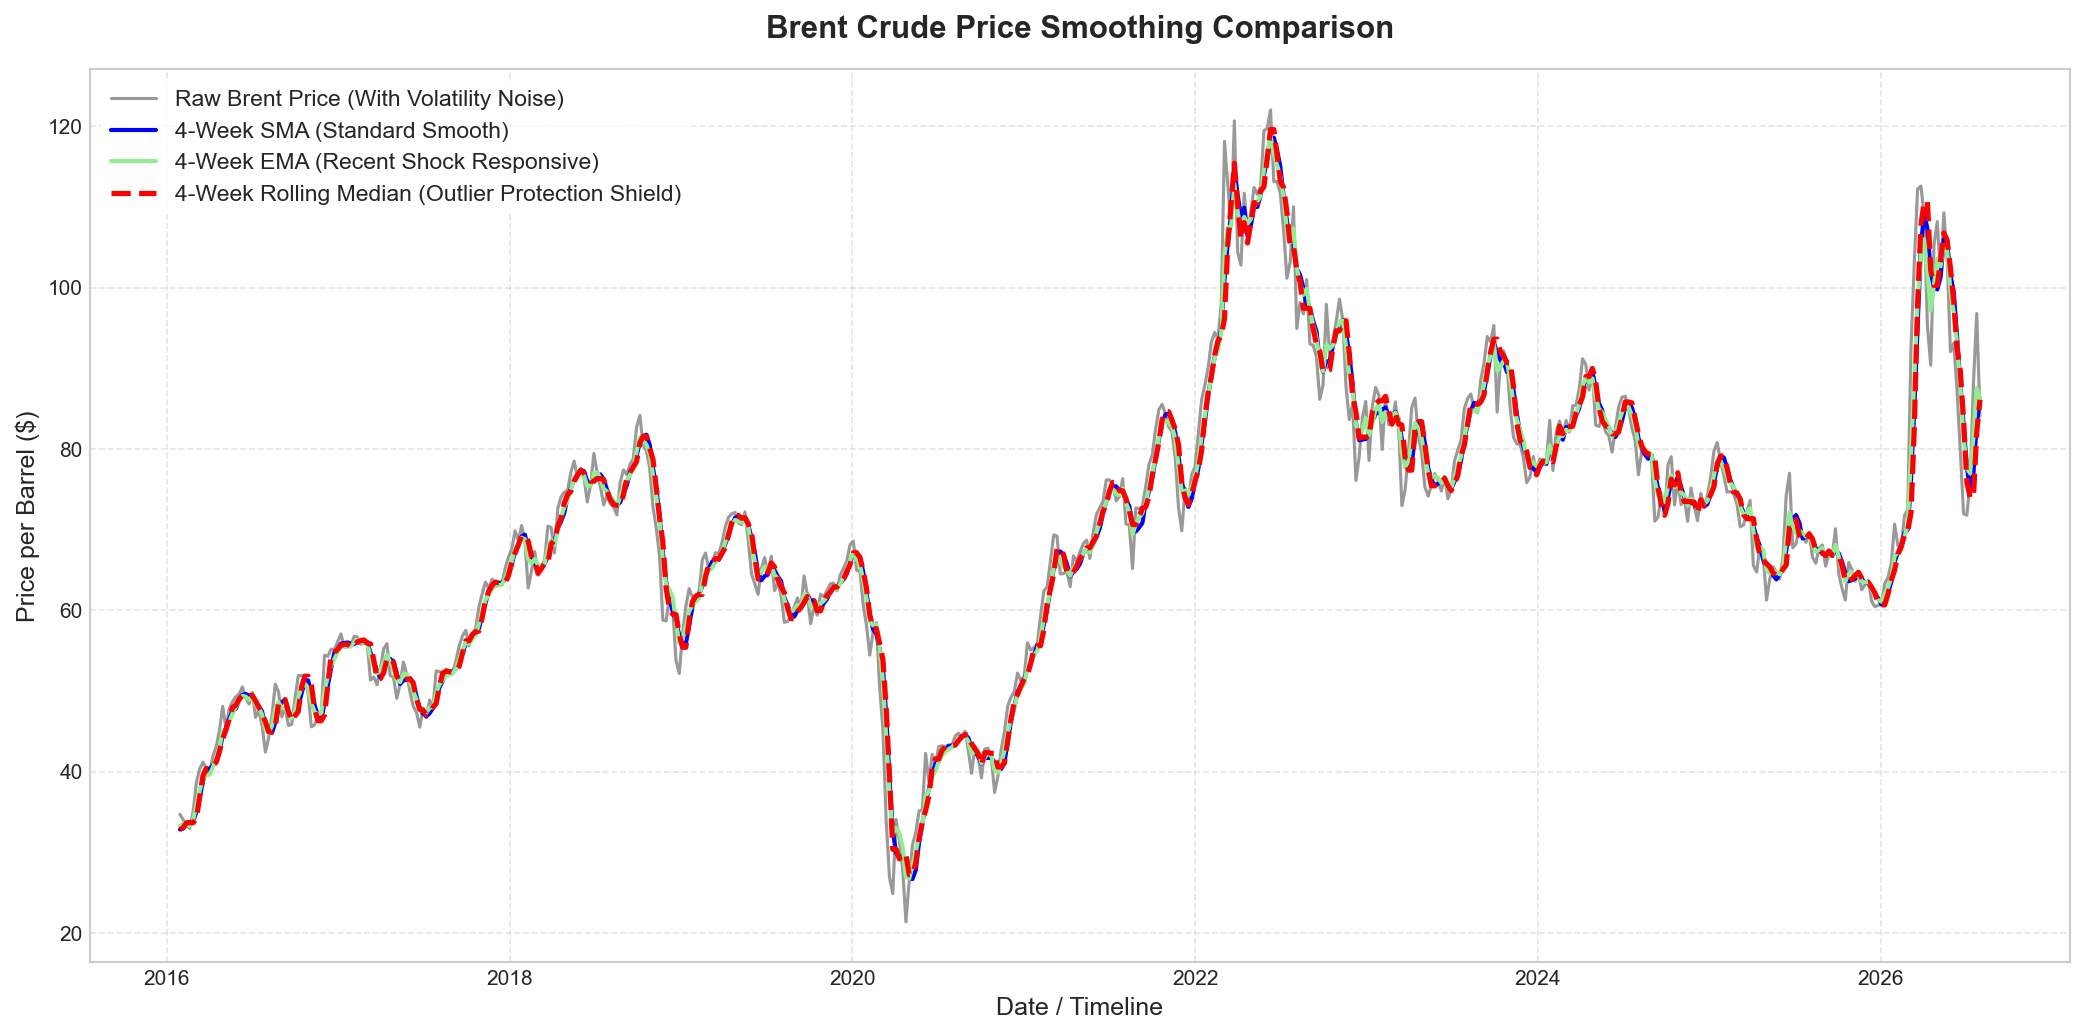

Brent Crude P-Value: 0.2336
-> Result: Brent Crude is Non-Stationary (Mountain). We must difference it for SARIMAX.
OPEC Supply P-Value: 0.4805
-> Result: OPEC Supply is Non-Stationary.


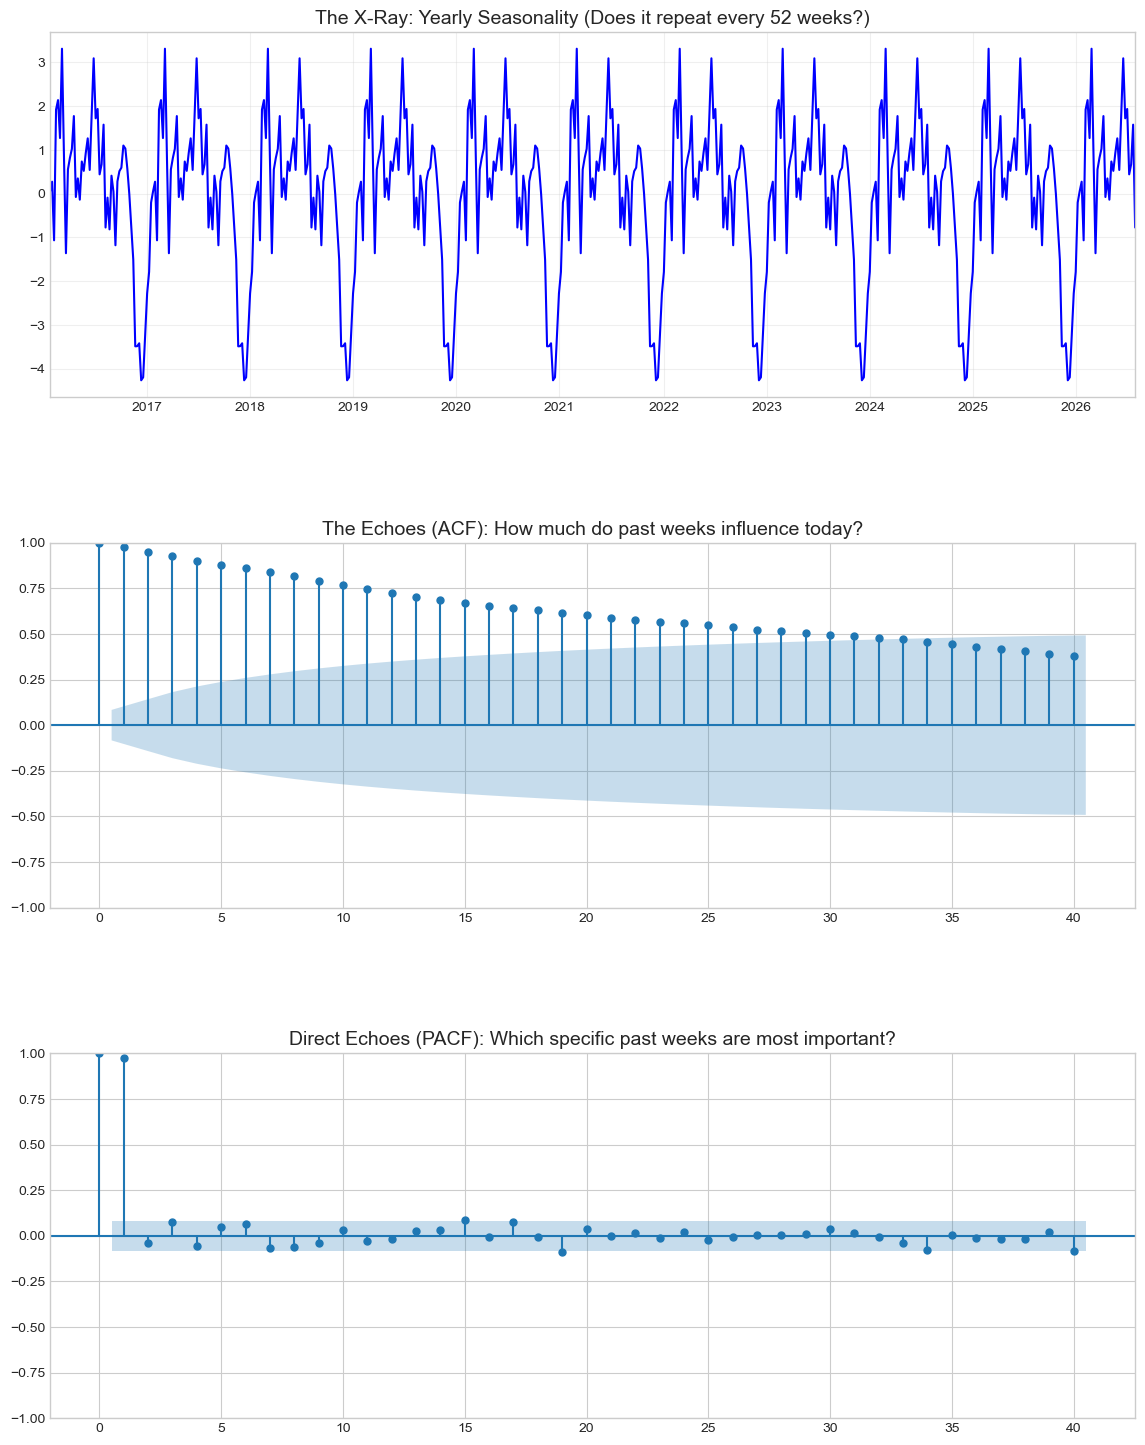

            Brent_Crude  WTI_Crude  US_Dollar_Index  VIX_Index  OPEC_Plus_Production
2026-07-03        71.80      68.69           100.86      16.15                27.517
2026-07-10        76.01      71.41           100.97      15.03                27.517
2026-07-17        88.10      82.49           100.75      18.77                27.517
2026-07-24        96.78      89.31           101.43      18.70                27.517
2026-07-31        84.09      79.26           101.51      18.67                27.517


In [1]:
# Load master dataset from EDA notebook
%run data_collection_cleaning_EDA.ipynb

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Set random seeds for reproducibility
np.random.seed(42)
tf.random.set_seed(42)

print(f"TensorFlow Version: {tf.__version__}")

TensorFlow Version: 2.18.0


In [3]:
print("\n--- 1. DATA PREPARATION & SLIDING WINDOW SEQUENCES ---")

# Select feature columns (Brent Crude + exogenous indicators)
feature_cols = ['Brent_Crude', 'WTI_Crude', 'US_Dollar_Index', 'VIX_Index', 'OPEC_Plus_Production']
target_col = 'Brent_Crude'
target_idx = feature_cols.index(target_col)

# Extract data matrix
data_matrix = master_dataset[feature_cols].copy().values

# 80/20 Chronological Split
train_size = int(len(data_matrix) * 0.8)
train_raw = data_matrix[:train_size]
test_raw = data_matrix[train_size:]

# Scale features using MinMaxScaler fitted strictly on training data
scaler = MinMaxScaler(feature_range=(0, 1))
train_scaled = scaler.fit_transform(train_raw)
test_scaled = scaler.transform(test_raw)

# Separate scaler for target variable to allow inverse transformation
target_scaler = MinMaxScaler(feature_range=(0, 1))
target_scaler.fit(train_raw[:, [target_idx]])

def create_sequences(data, lookback=4, target_index=0):
    X, y = [], []
    for i in range(lookback, len(data)):
        X.append(data[i-lookback:i, :])
        y.append(data[i, target_index])
    return np.array(X), np.array(y)

LOOKBACK_WEEKS = 4  # 4-week memory window
X_train, y_train = create_sequences(train_scaled, lookback=LOOKBACK_WEEKS, target_index=target_idx)

# For test set, concatenate last LOOKBACK_WEEKS of train set to evaluate all test points
full_test_scaled = np.vstack([train_scaled[-LOOKBACK_WEEKS:], test_scaled])
X_test, y_test = create_sequences(full_test_scaled, lookback=LOOKBACK_WEEKS, target_index=target_idx)

print(f"Train Sequences: X={X_train.shape}, y={y_train.shape}")
print(f"Test Sequences:  X={X_test.shape}, y={y_test.shape}")


--- 1. DATA PREPARATION & SLIDING WINDOW SEQUENCES ---
Train Sequences: X=(435, 4, 5), y=(435,)
Test Sequences:  X=(110, 4, 5), y=(110,)


In [4]:
print("\n--- 2. TENSORFLOW / KERAS LSTM MODEL BUILDING ---")

model = Sequential([
    LSTM(64, return_sequences=True, input_shape=(LOOKBACK_WEEKS, len(feature_cols))),
    Dropout(0.2),
    LSTM(32, return_sequences=False),
    Dropout(0.2),
    Dense(16, activation='relu'),
    Dense(1)
])

model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001), loss='mean_squared_error')
model.summary()


--- 2. TENSORFLOW / KERAS LSTM MODEL BUILDING ---


/opt/anaconda3/lib/python3.12/site-packages/keras/src/layers/rnn/rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 4, 64)          │        17,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 4, 64)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 30,881 (120.63 KB)

 Trainable params: 30,881 (120.63 KB)

 Non-trainable params: 0 (0.00 B)


--- 3. MODEL TRAINING ---
Epoch 1/100



 1/24 ━━━━━━━━━━━━━━━━━━━━ 37s 2s/step - loss: 0.2392


 2/24 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.2218


24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.1487


24/24 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - loss: 0.1465 - val_loss: 0.0081


Epoch 2/100


... (150 outputs left out)

Epoch 49/100



 1/24 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.0028


18/24 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0028 


24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0028 - val_loss: 0.0020


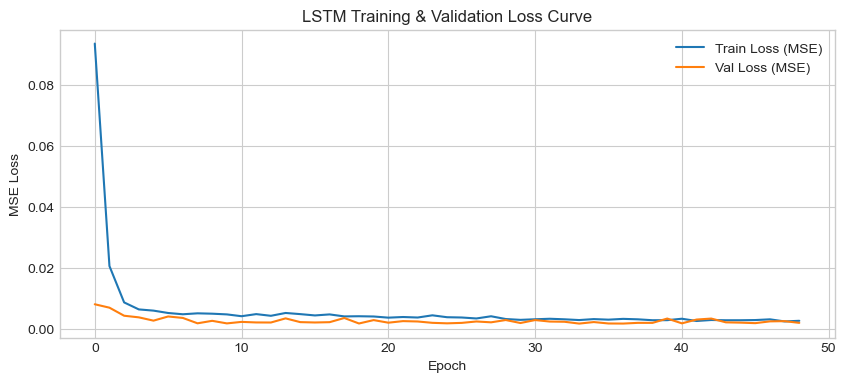

In [5]:
print("\n--- 3. MODEL TRAINING ---")

early_stop = EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True)

history = model.fit(
    X_train, y_train,
    epochs=100,
    batch_size=16,
    validation_split=0.15,
    callbacks=[early_stop],
    verbose=1
)

plt.figure(figsize=(10, 4))
plt.plot(history.history['loss'], label='Train Loss (MSE)')
plt.plot(history.history['val_loss'], label='Val Loss (MSE)')
plt.title('LSTM Training & Validation Loss Curve')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.legend()
plt.grid(True)
plt.show()

In [6]:
print("\n--- 4. TEST PREDICTIONS & EVALUATION METRICS ---")

# Predict on test set
y_pred_scaled = model.predict(X_test)

# Inverse scale predictions and actual targets back to USD
y_test_actual = target_scaler.inverse_transform(y_test.reshape(-1, 1)).flatten()
y_pred_actual = target_scaler.inverse_transform(y_pred_scaled).flatten()

# Test Dates matching the test sequence
test_dates = master_dataset.index[train_size:]

# Calculate Performance Metrics
rmse = np.sqrt(mean_squared_error(y_test_actual, y_pred_actual))
mae = mean_absolute_error(y_test_actual, y_pred_actual)
mape = np.mean(np.abs((y_test_actual - y_pred_actual) / y_test_actual)) * 100
r2 = r2_score(y_test_actual, y_pred_actual)

# Directional Accuracy (DA)
actual_direction = np.sign(np.diff(y_test_actual))
pred_direction = np.sign(np.diff(y_pred_actual))
da = np.mean(actual_direction == pred_direction) * 100

print("========================================")
print("      LSTM MODEL TEST PERFORMANCE      ")
print("========================================")
print(f"Root Mean Squared Error (RMSE) : ${rmse:.2f}")
print(f"Mean Absolute Error (MAE)      : ${mae:.2f}")
print(f"Mean Absolute Pct Error (MAPE) : {mape:.2f}%")
print(f"R-Squared (R²) Score          : {r2:.4f}")
print(f"Directional Accuracy (DA)      : {da:.2f}%")
print("========================================")


--- 4. TEST PREDICTIONS & EVALUATION METRICS ---



1/4 ━━━━━━━━━━━━━━━━━━━━ 0s 236ms/step


4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step 


4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step


      LSTM MODEL TEST PERFORMANCE      
Root Mean Squared Error (RMSE) : $7.66
Mean Absolute Error (MAE)      : $4.87
Mean Absolute Pct Error (MAPE) : 5.89%
R-Squared (R²) Score          : 0.6204
Directional Accuracy (DA)      : 52.29%



--- 5. VISUALIZATION: ACTUAL VS LSTM PREDICTED PRICES ---


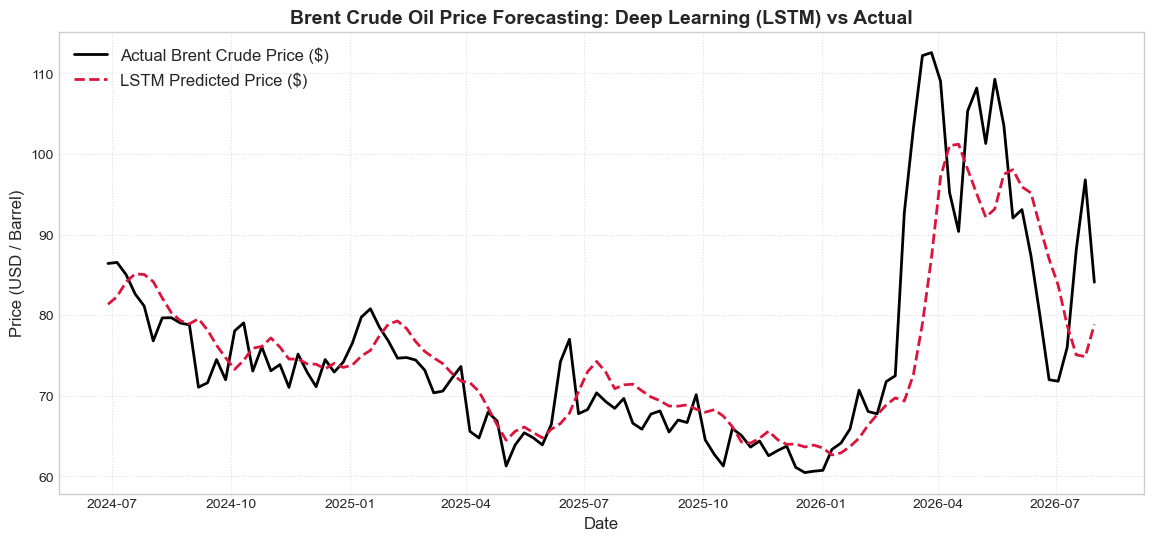

In [7]:
print("\n--- 5. VISUALIZATION: ACTUAL VS LSTM PREDICTED PRICES ---")

plt.figure(figsize=(14, 6))
plt.plot(test_dates, y_test_actual, label='Actual Brent Crude Price ($)', color='black', lw=2)
plt.plot(test_dates, y_pred_actual, label='LSTM Predicted Price ($)', color='crimson', linestyle='--', lw=2)
plt.title('Brent Crude Oil Price Forecasting: Deep Learning (LSTM) vs Actual', fontsize=14, fontweight='bold')
plt.xlabel('Date', fontsize=12)
plt.ylabel('Price (USD / Barrel)', fontsize=12)
plt.legend(fontsize=12)
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

In [8]:
import os
# Ensure data_processed directory exists
os.makedirs('../data_processed', exist_ok=True)

# Export predictions to CSV for seamless import in master comparison
lstm_df = pd.DataFrame({
    'Actual_Brent': y_test_actual,
    'LSTM_Pred': y_pred_actual
}, index=test_dates)

lstm_df.to_csv('../data_processed/lstm_test_predictions.csv')
print("LSTM Test Predictions saved successfully to '../data_processed/lstm_test_predictions.csv'.")

LSTM Test Predictions saved successfully to '../data_processed/lstm_test_predictions.csv'.


### Summary of Deep Learning (LSTM) Baseline Results

- **Performance Overview**: The baseline TensorFlow LSTM model captures non-linear temporal patterns across historical price memory and macro-economic signals (WTI, DXY, VIX, OPEC+).
- **Next Steps**: Update `master_ml_comparison.ipynb` to compare **SARIMAX (Statistical)**, **XGBoost (Machine Learning)**, and **LSTM (Deep Learning)** side-by-side.